# Mouse pseudotime already on the object — violins and spatial plots

**Loads, does not compute.** Reads `dpt_pseudotime` as it currently stands on the netscratch mouse fib/dec
object and plots it raw and quantile-normalised. No scVI, no root choice, no DPT/Palantir run — CPU only,
a couple of minutes.

**Object:** `/n/netscratch/eddy_lab/Everyone/nhilgert/2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad`
(43,197 cells; `x_um_qc`/`y_um_qc`/`tissue_section` from the settled 5-MAD spatial QC. The `2026_08_28`
copy in the same folder carries a `dpt_pseudotime` with identical statistics — same values, older QC.)

**Provenance of the loaded pseudotime**, per the user and the object's own provenance strings: moscot
TemporalProblem → CellRank RealTimeKernel → DPT. §1 prints whatever the object records, and reports coverage —
worth reading, because **all 43,197 cells carry a value**, i.e. more than the 32,957 of the `baseline_v2`
(induced, non-apoptotic) run, so this is the all-cells version and it includes `decidual_apoptotic` and
uninduced cells.

**Quantile normalisation.** `dpt_q` = each cell's percentile among all cells with a value (`rank(pct=True)`):
identical ordering (asserted in §2), uniform spacing, so the compressed part of the distribution becomes
readable in the colour scale without dropping cells. `dpt_qsec` normalises within tissue section — for
comparing trajectory *shape* between sections only; by construction every section then spans 0–1, so it
cannot say one section is further along.

Nothing here writes to the object.

In [1]:
import pathlib, json, h5py, warnings
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
try:    from anndata.io import read_elem
except ImportError: from anndata.experimental import read_elem

N   = pathlib.Path("/n/netscratch/eddy_lab/Everyone/nhilgert")
SRC = N/"2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"
OUT = pathlib.Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/pseudotime_loaded_mouse")
OUT.mkdir(parents=True, exist_ok=True)
PTCOL = "dpt_pseudotime"

SUBORDER = ["efib_outer","efib_middle","efib_middle_induced","efib_subluminal","efib_proliferative",
            "decidual_boundary","decidual_proliferative","decidual_mature","decidual_apoptotic"]
TPORDER  = ["uninduced","1_dpi_early","1_dpi_late","2_dpi","3_dpi","4_dpi_bleeding"]
RANK, TPRANK = {s:i for i,s in enumerate(SUBORDER)}, {t:i for i,t in enumerate(TPORDER)}
PAL  = dict(zip(SUBORDER, sns.color_palette("viridis", len(SUBORDER))))
TPAL = dict(zip(TPORDER,  sns.color_palette("rocket_r", len(TPORDER))))

CHECKS = []
def verify(label, got, note=""):
    ok = bool(got); CHECKS.append((label, ok, str(got), note))
    print(("PASS  " if ok else "FAIL  ") + label + f"   [{got}]" + (f"  {note}" if note else "")); return ok
print("source:", SRC, "| exists:", SRC.exists())

source: /n/netscratch/eddy_lab/Everyone/nhilgert/2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad | exists: True


## 1 — load obs only (no expression matrix needed) and read the provenance

In [2]:
WANT = [PTCOL, "cell_subtype", "cell_type", "timepoint", "sample",
        "x_um_qc", "y_um_qc", "tissue_section", "spatial_qc_reason"]
with h5py.File(SRC, "r") as f:
    have = [c for c in WANT if c in f["obs"].keys()]
    missing = [c for c in WANT if c not in have]
    res = pd.DataFrame({c: np.asarray(read_elem(f[f"obs/{c}"])).ravel() for c in have},
                       index=pd.Index(np.asarray(read_elem(f["obs/_index"])).ravel(), name="cell"))
    prov_cols = [c for c in f["obs"].keys() if "provenance" in c or "root" in c]
    prov = {c: str(np.asarray(read_elem(f[f"obs/{c}"])).ravel()[0]) for c in prov_cols}
    uns_pt = {k: read_elem(f[f"uns/{k}"]) for k in f["uns"].keys() if "pseudo" in k.lower() or "dpt" in k.lower()}
print("loaded obs:", res.shape, "| missing:", missing)
for c in ("cell_subtype","cell_type","timepoint","sample","tissue_section","spatial_qc_reason"):
    if c in res: res[c] = res[c].astype(str)
res[PTCOL] = pd.to_numeric(res[PTCOL], errors="coerce")
for c in ("x_um_qc","y_um_qc"): res[c] = pd.to_numeric(res[c], errors="coerce")

print("\n=== provenance recorded on the object ===")
for k, v in prov.items(): print(f"\nobs['{k}']:\n  {v[:900]}")
for k, v in uns_pt.items(): print(f"\nuns['{k}']: {json.dumps(v, default=str)[:600]}")
if not prov and not uns_pt: print("  (no provenance string found on this object)")

verify(f"{PTCOL} present", PTCOL in res.columns)
verify("QC'd coordinates + tissue_section present", {"x_um_qc","y_um_qc","tissue_section"} <= set(res.columns))
print(f"\ncoverage: {int(res[PTCOL].notna().sum()):,} of {len(res):,} cells have a pseudotime value")
print(f"range: min {res[PTCOL].min():.4g}  median {res[PTCOL].median():.4g}  max {res[PTCOL].max():.4g}")
print("\nfinite pseudotime by timepoint:"); display(pd.crosstab(res.timepoint, res[PTCOL].notna()).reindex(TPORDER))
print("finite pseudotime by subtype:");    display(pd.crosstab(res.cell_subtype, res[PTCOL].notna()).reindex([s for s in SUBORDER if s in set(res.cell_subtype)]))

loaded obs: (43197, 9) | missing: []

=== provenance recorded on the object ===
  (no provenance string found on this object)
PASS  dpt_pseudotime present   [True]
PASS  QC'd coordinates + tissue_section present   [True]

coverage: 43,197 of 43,197 cells have a pseudotime value
range: min 0  median 0.4145  max 1

finite pseudotime by timepoint:


dpt_pseudotime,True
timepoint,
uninduced,9334
1_dpi_early,2688
1_dpi_late,10787
2_dpi,3574
3_dpi,10673
4_dpi_bleeding,6141


finite pseudotime by subtype:


dpt_pseudotime,True
cell_subtype,
efib_outer,2073
efib_middle,4764
efib_middle_induced,8775
efib_subluminal,3886
efib_proliferative,780
decidual_boundary,3722
decidual_proliferative,14434
decidual_mature,3856
decidual_apoptotic,907


## 2 — quantile normalise

`dpt_q` global, `dpt_qsec` within tissue section. Ordering preservation is asserted — that is the entire justification for using the quantile version in a figure.

PASS  quantile transform preserves the ordering exactly   [True]
median by subtype:


,raw,quantile
cell_subtype,,
efib_outer,0.303,0.025
efib_middle,0.393,0.167
efib_middle_induced,0.400,0.269
efib_subluminal,0.406,0.370
efib_proliferative,0.405,0.351
decidual_boundary,0.421,0.570
decidual_proliferative,0.435,0.715
decidual_mature,0.474,0.929
decidual_apoptotic,0.565,0.989


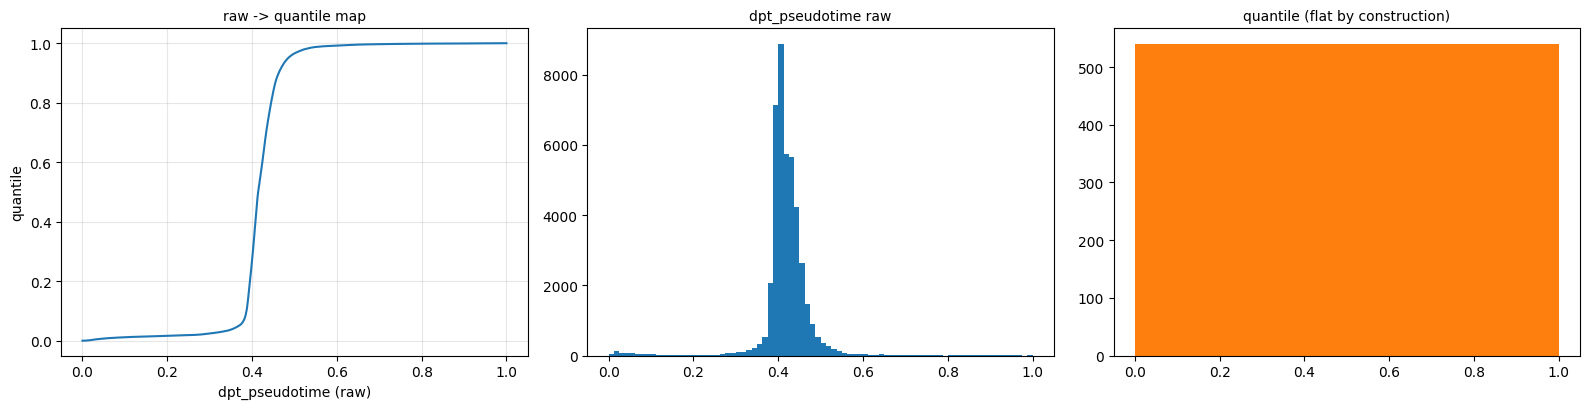

In [3]:
res["dpt_q"]    = res[PTCOL].rank(pct=True)
res["dpt_qsec"] = res.groupby("tissue_section", observed=True)[PTCOL].rank(pct=True)
m = res[PTCOL].notna()
verify("quantile transform preserves the ordering exactly",
       float(spearmanr(res.loc[m, PTCOL], res.loc[m, "dpt_q"]).statistic) == 1.0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
v = np.sort(res.loc[m, PTCOL].to_numpy())
axes[0].plot(v, np.linspace(0, 1, len(v)), lw=1.5); axes[0].grid(alpha=.3)
axes[0].set_xlabel(f"{PTCOL} (raw)"); axes[0].set_ylabel("quantile"); axes[0].set_title("raw -> quantile map", fontsize=10)
axes[1].hist(res.loc[m, PTCOL], bins=80, color="C0"); axes[1].set_title(f"{PTCOL} raw", fontsize=10)
axes[2].hist(res.loc[m, "dpt_q"], bins=80, color="C1"); axes[2].set_title("quantile (flat by construction)", fontsize=10)
fig.tight_layout()

print("median by subtype:")
display(pd.DataFrame({"raw": res.groupby("cell_subtype")[PTCOL].median(),
                      "quantile": res.groupby("cell_subtype").dpt_q.median()}
                     ).reindex([s for s in SUBORDER if s in set(res.cell_subtype)]).round(3))

## 3 — how this pseudotime is oriented

Descriptive, not a gate — nothing is being recomputed here. Pooled day correlation is confounded by composition (later sections are mostly decidual), so the compartment-split versions are the informative ones. The row restricted to the induced, non-apoptotic cells is the `baseline_v2` cell set, for comparison with numbers quoted from that run.

In [4]:
sr = res.cell_subtype.map(RANK); tr = res.timepoint.map(TPRANK)
def block(mask, label):
    mm = mask & res[PTCOL].notna() & sr.notna() & tr.notna()
    if mm.sum() < 50: return None
    return dict(subset=label, n=int(mm.sum()),
                rho_subtype_rank=round(float(spearmanr(res.loc[mm, PTCOL], sr[mm]).statistic), 4),
                rho_day=round(float(spearmanr(res.loc[mm, PTCOL], tr[mm]).statistic), 4))
fib = res.cell_subtype.str.startswith("efib"); dec = ~fib
rows = [block(pd.Series(True, index=res.index), "all cells"),
        block(fib, "fibroblasts only"),
        block(dec, "decidual only"),
        block((res.timepoint != "uninduced") & (res.cell_subtype != "decidual_apoptotic"), "induced, non-apoptotic (= baseline_v2 cell set)"),
        block(res.timepoint == "uninduced", "uninduced only")]
display(pd.DataFrame([r for r in rows if r]).set_index("subset"))
print("median quantile pseudotime by timepoint x compartment:")
res["compartment"] = np.where(fib, "fibroblast", "decidual")
display(res.pivot_table(index="timepoint", columns="compartment", values="dpt_q", aggfunc="median", observed=True).reindex(TPORDER).round(3))

,n,rho_subtype_rank,rho_day
subset,,,
all cells,43197,0.8831,0.6654
fibroblasts only,20278,0.5852,0.2538
decidual only,22919,0.6821,0.5335
"induced, non-apoptotic (= baseline_v2 cell set)",32957,0.8397,0.5153
uninduced only,9334,0.7307,NaN


median quantile pseudotime by timepoint x compartment:


compartment,decidual,fibroblast
timepoint,,
uninduced,0.304,0.198
1_dpi_early,0.459,0.221
1_dpi_late,0.602,0.224
2_dpi,0.681,0.255
3_dpi,0.776,0.389
4_dpi_bleeding,0.845,0.437


## 4 — violins, raw and quantile

By subtype, by timepoint, and by sample. Colour encodes the category only; the black bar is the median.

,dpt_pseudotime,dpt_q
cell_subtype,,
efib_outer,0.3029,0.0245
efib_middle,0.3926,0.1673
efib_middle_induced,0.3999,0.2693
efib_subluminal,0.4061,0.3698
efib_proliferative,0.4051,0.3506
decidual_boundary,0.4213,0.5695
decidual_proliferative,0.4348,0.7145
decidual_mature,0.4736,0.9295
decidual_apoptotic,0.5654,0.9894


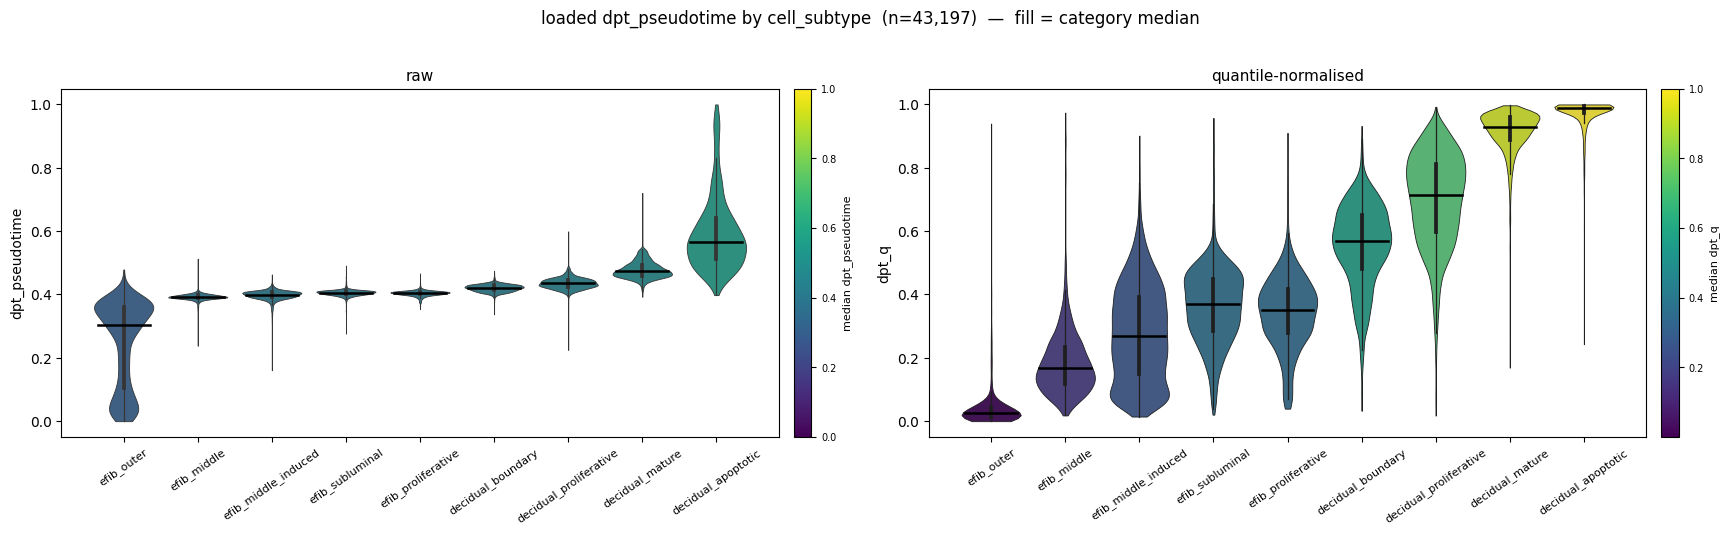

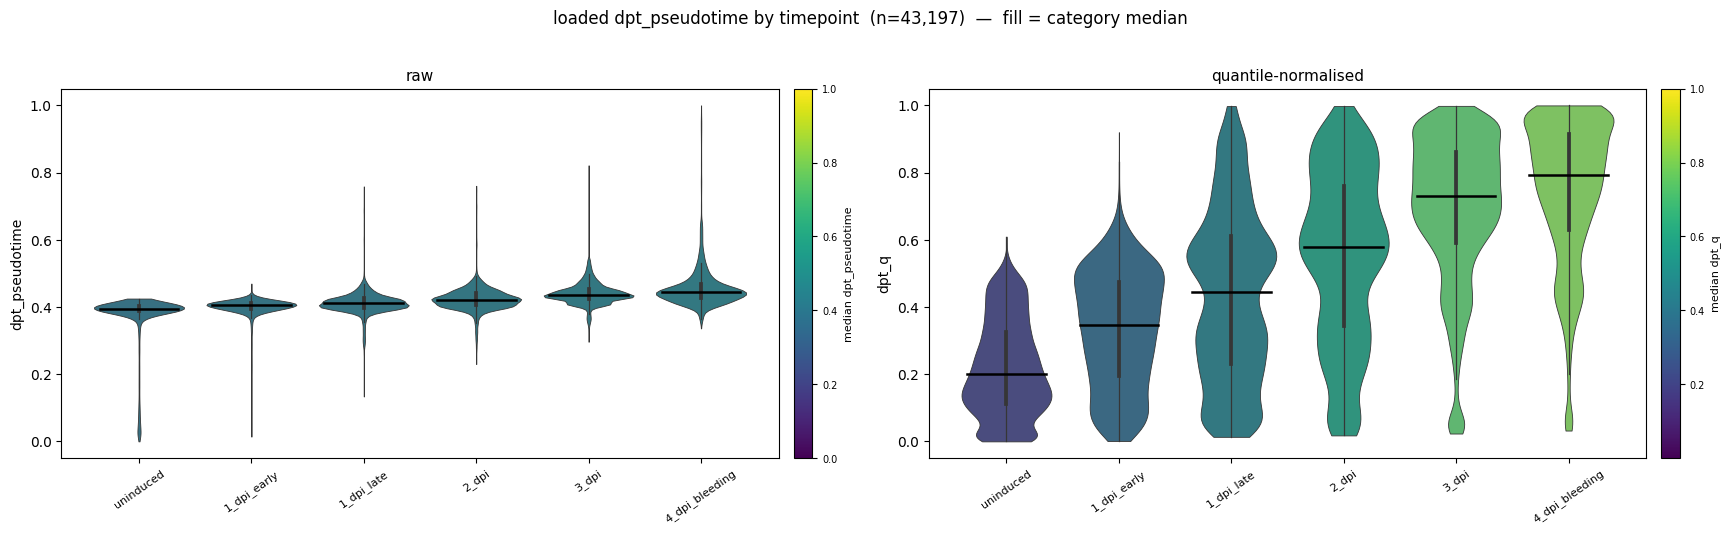

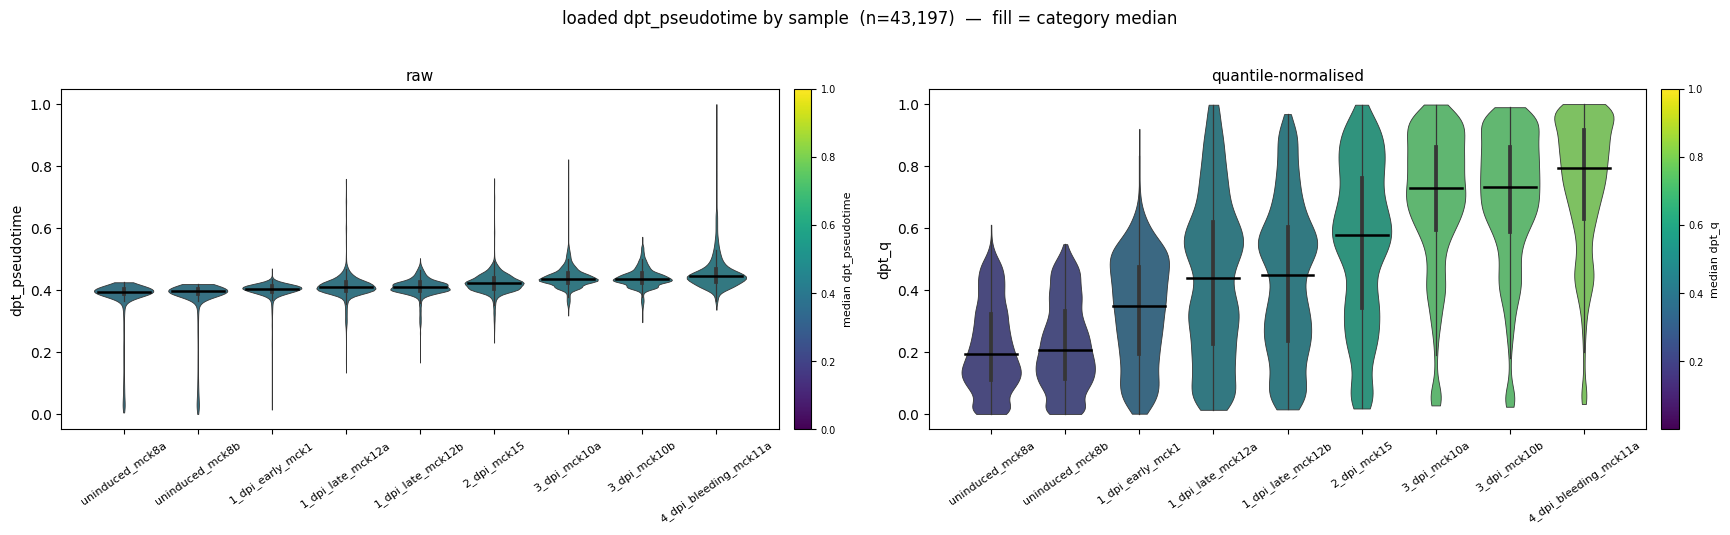

In [8]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

def violins(by, order=None, pal=None, cmap="viridis", vlim=None, figsize=(17.5, 5.2)):
    """Violins of the loaded pseudotime, raw beside quantile-normalised.

    Fill colour = that category's MEDIAN of the column plotted, on the same colour scale the spatial
    panels use for that column, so a violin's colour is the colour the tissue takes at that category's
    typical position. The two panels are coloured independently because their medians are on different
    scales (raw = data range, quantile = 0-1). Black bar = median; violin outline = distribution.

    vlim: {column: (vmin, vmax)} to force the scale.
    pal:  {cat: colour} falls back to categorical colouring.
    """
    order = order or [s for s in (SUBORDER if by == "cell_subtype" else TPORDER) if s in set(res[by])]
    d = res[res[PTCOL].notna()]
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True)
    meds = {}
    for ax, col in zip(axes, (PTCOL, "dpt_q")):
        med = d.groupby(by, observed=True)[col].median().reindex(order); meds[col] = med
        if pal is None:
            lo, hi = (vlim or {}).get(col, (float(d[col].min()), float(d[col].max())))
            norm = Normalize(vmin=lo, vmax=hi)
            colours = {c_: plt.get_cmap(cmap)(norm(med[c_])) for c_ in order if pd.notna(med[c_])}
            sm = ScalarMappable(norm=norm, cmap=cmap)
        else:
            colours, sm = pal, None
        sns.violinplot(data=d, x=by, y=col, order=order, hue=by, hue_order=order,
                       palette=colours, legend=False, cut=0, linewidth=.6, ax=ax)
        for k, c_ in enumerate(order):
            if pd.notna(med.get(c_)): ax.plot([k-.35, k+.35], [med[c_]]*2, c="k", lw=1.8, zorder=5)
        ax.set_title("raw" if col == PTCOL else "quantile-normalised", fontsize=11)
        ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35, labelsize=8)
        if sm is not None:
            cb = fig.colorbar(sm, ax=ax, fraction=.046, pad=.02)
            cb.set_label(f"median {col}", fontsize=8); cb.ax.tick_params(labelsize=7)
    fig.suptitle(f"loaded {PTCOL} by {by}  (n={len(d):,})  —  fill = category median", y=1.02)
    fig.tight_layout(); return fig, pd.DataFrame(meds).round(4)

fig, MED = violins("cell_subtype"); display(MED)
fig, _   = violins("timepoint")
SAMPLE_ORDER = [s for t in TPORDER for s in sorted(res["sample"].unique()) if s.startswith(t)]
fig, _   = violins("sample", SAMPLE_ORDER)

## 5 — spatial: raw, quantile (global), quantile (within section)

One row per tissue section, ordered by timepoint. Raw and global-quantile share one colour scale across all sections so panels are comparable; within-section is 0–1 by construction. Sections are never pooled within a timepoint — pucks from the same timepoint share a coordinate frame, so overlaying them would superimpose different pieces of tissue.

23,647 of 43,197 cells have both a pseudotime and a QC'd coordinate | 11 sections


tissue_section,uninduced_mck8a__A,uninduced_mck8a__B,uninduced_mck8b__A,uninduced_mck8b__B,1_dpi_early_mck1__A,1_dpi_late_mck12a__A,1_dpi_late_mck12b__A,2_dpi_mck15__A,3_dpi_mck10a__A,3_dpi_mck10b__A,4_dpi_bleeding_mck11a__A
n_cells,961,1066,906,966,1407,3451,1458,2127,3187,3582,4536


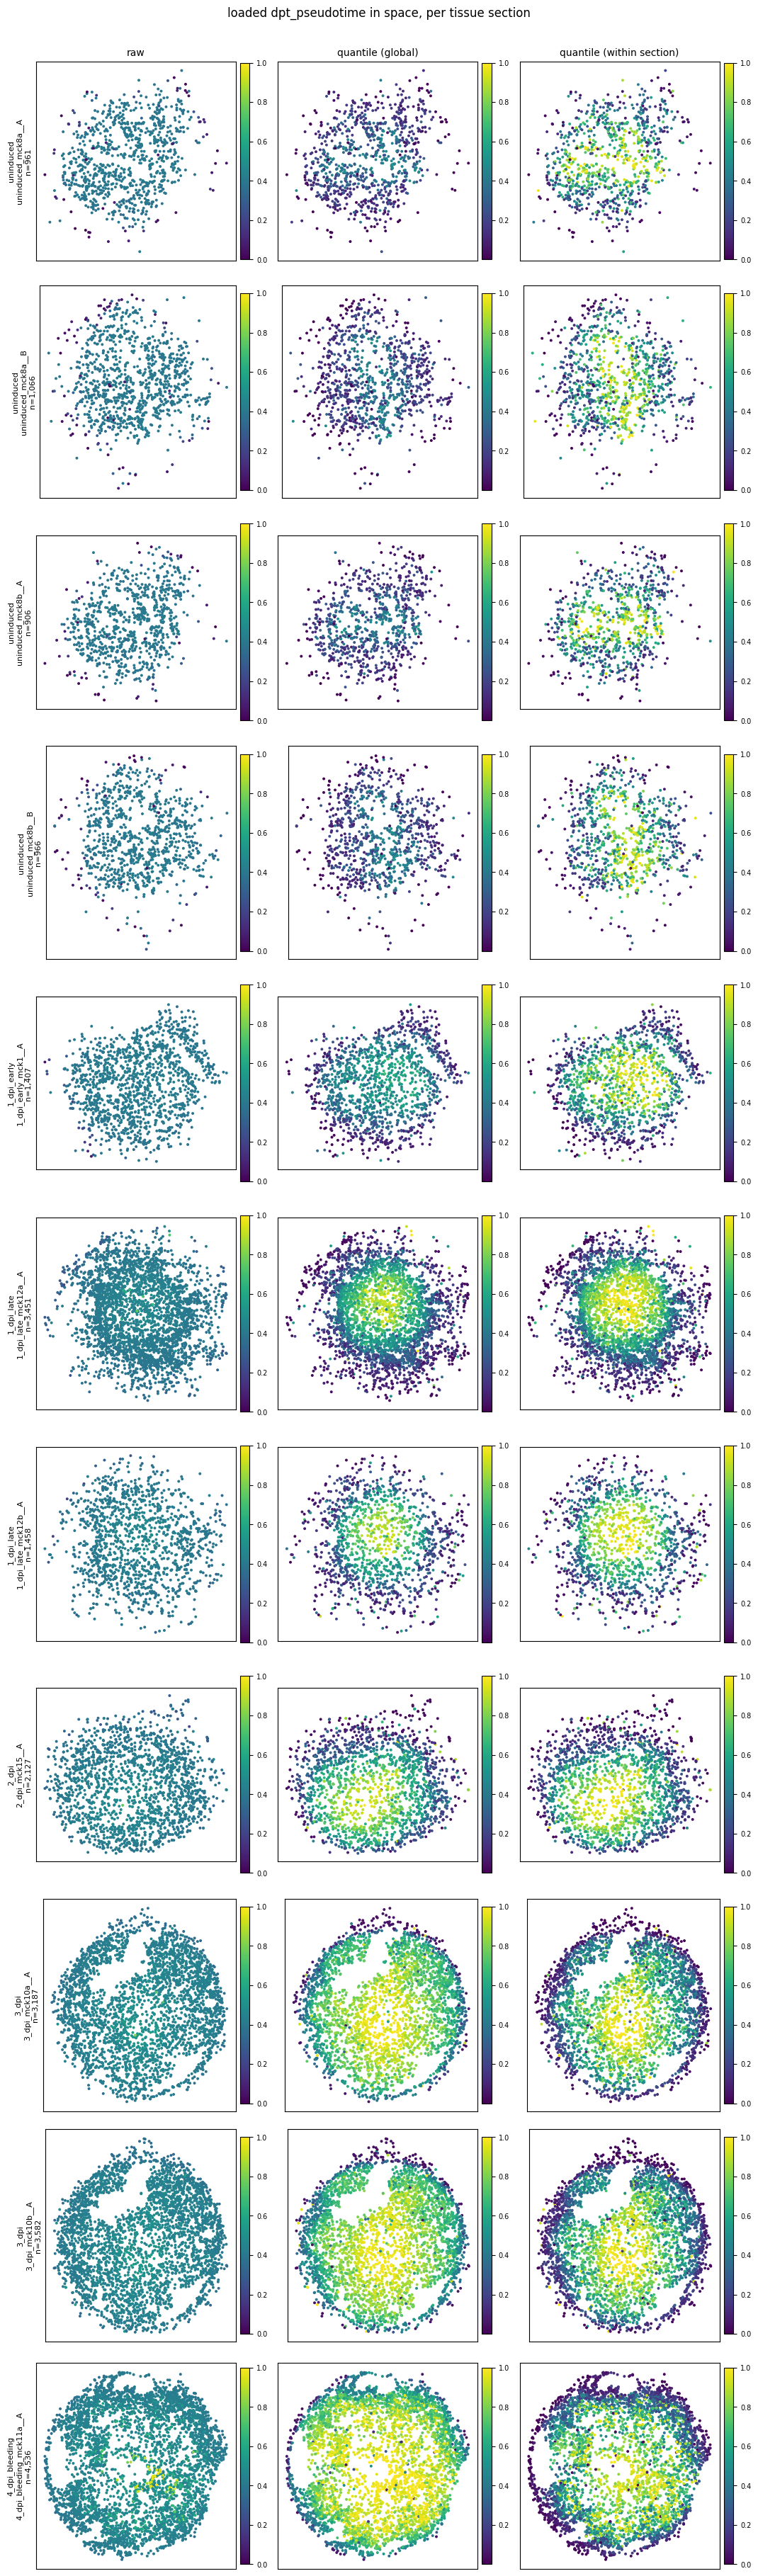

In [6]:
SP = res[res[PTCOL].notna() & np.isfinite(res.x_um_qc) & (res.tissue_section != "nan") & res.tissue_section.notna()].copy()
SEC2TP = SP.groupby("tissue_section", observed=True).timepoint.first().to_dict()
secs = sorted(SP.tissue_section.unique(), key=lambda s: (TPRANK.get(SEC2TP[s], 99), s))
SEC_BY_TP = {t: [s for s in secs if SEC2TP[s] == t] for t in TPORDER if any(SEC2TP[s] == t for s in secs)}
print(f"{len(SP):,} of {len(res):,} cells have both a pseudotime and a QC'd coordinate | {len(secs)} sections")
display(SP.groupby("tissue_section", observed=True).size().reindex(secs).rename("n_cells").to_frame().T)

COLS = (PTCOL, "dpt_q", "dpt_qsec"); LABS = {PTCOL:"raw", "dpt_q":"quantile (global)", "dpt_qsec":"quantile (within section)"}
def spatial_panels(per=3.6, s=3.4):
    fig, axes = plt.subplots(len(secs), len(COLS), figsize=(per*len(COLS), per*len(secs)*.92), squeeze=False)
    for i, sec in enumerate(secs):
        g = SP[SP.tissue_section == sec]
        for j, col in enumerate(COLS):
            ax = axes[i][j]; vmin, vmax = ((SP[col].min(), SP[col].max()) if col != "dpt_qsec" else (0, 1))
            sm = ax.scatter(g.x_um_qc, g.y_um_qc, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            if i == 0: ax.set_title(LABS[col], fontsize=10)
            if j == 0: ax.set_ylabel(f"{SEC2TP[sec]}\n{sec}\nn={len(g):,}", fontsize=8)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"loaded {PTCOL} in space, per tissue section", y=1.0); fig.tight_layout(); return fig
_ = spatial_panels()

### Same panels, organised by timepoint

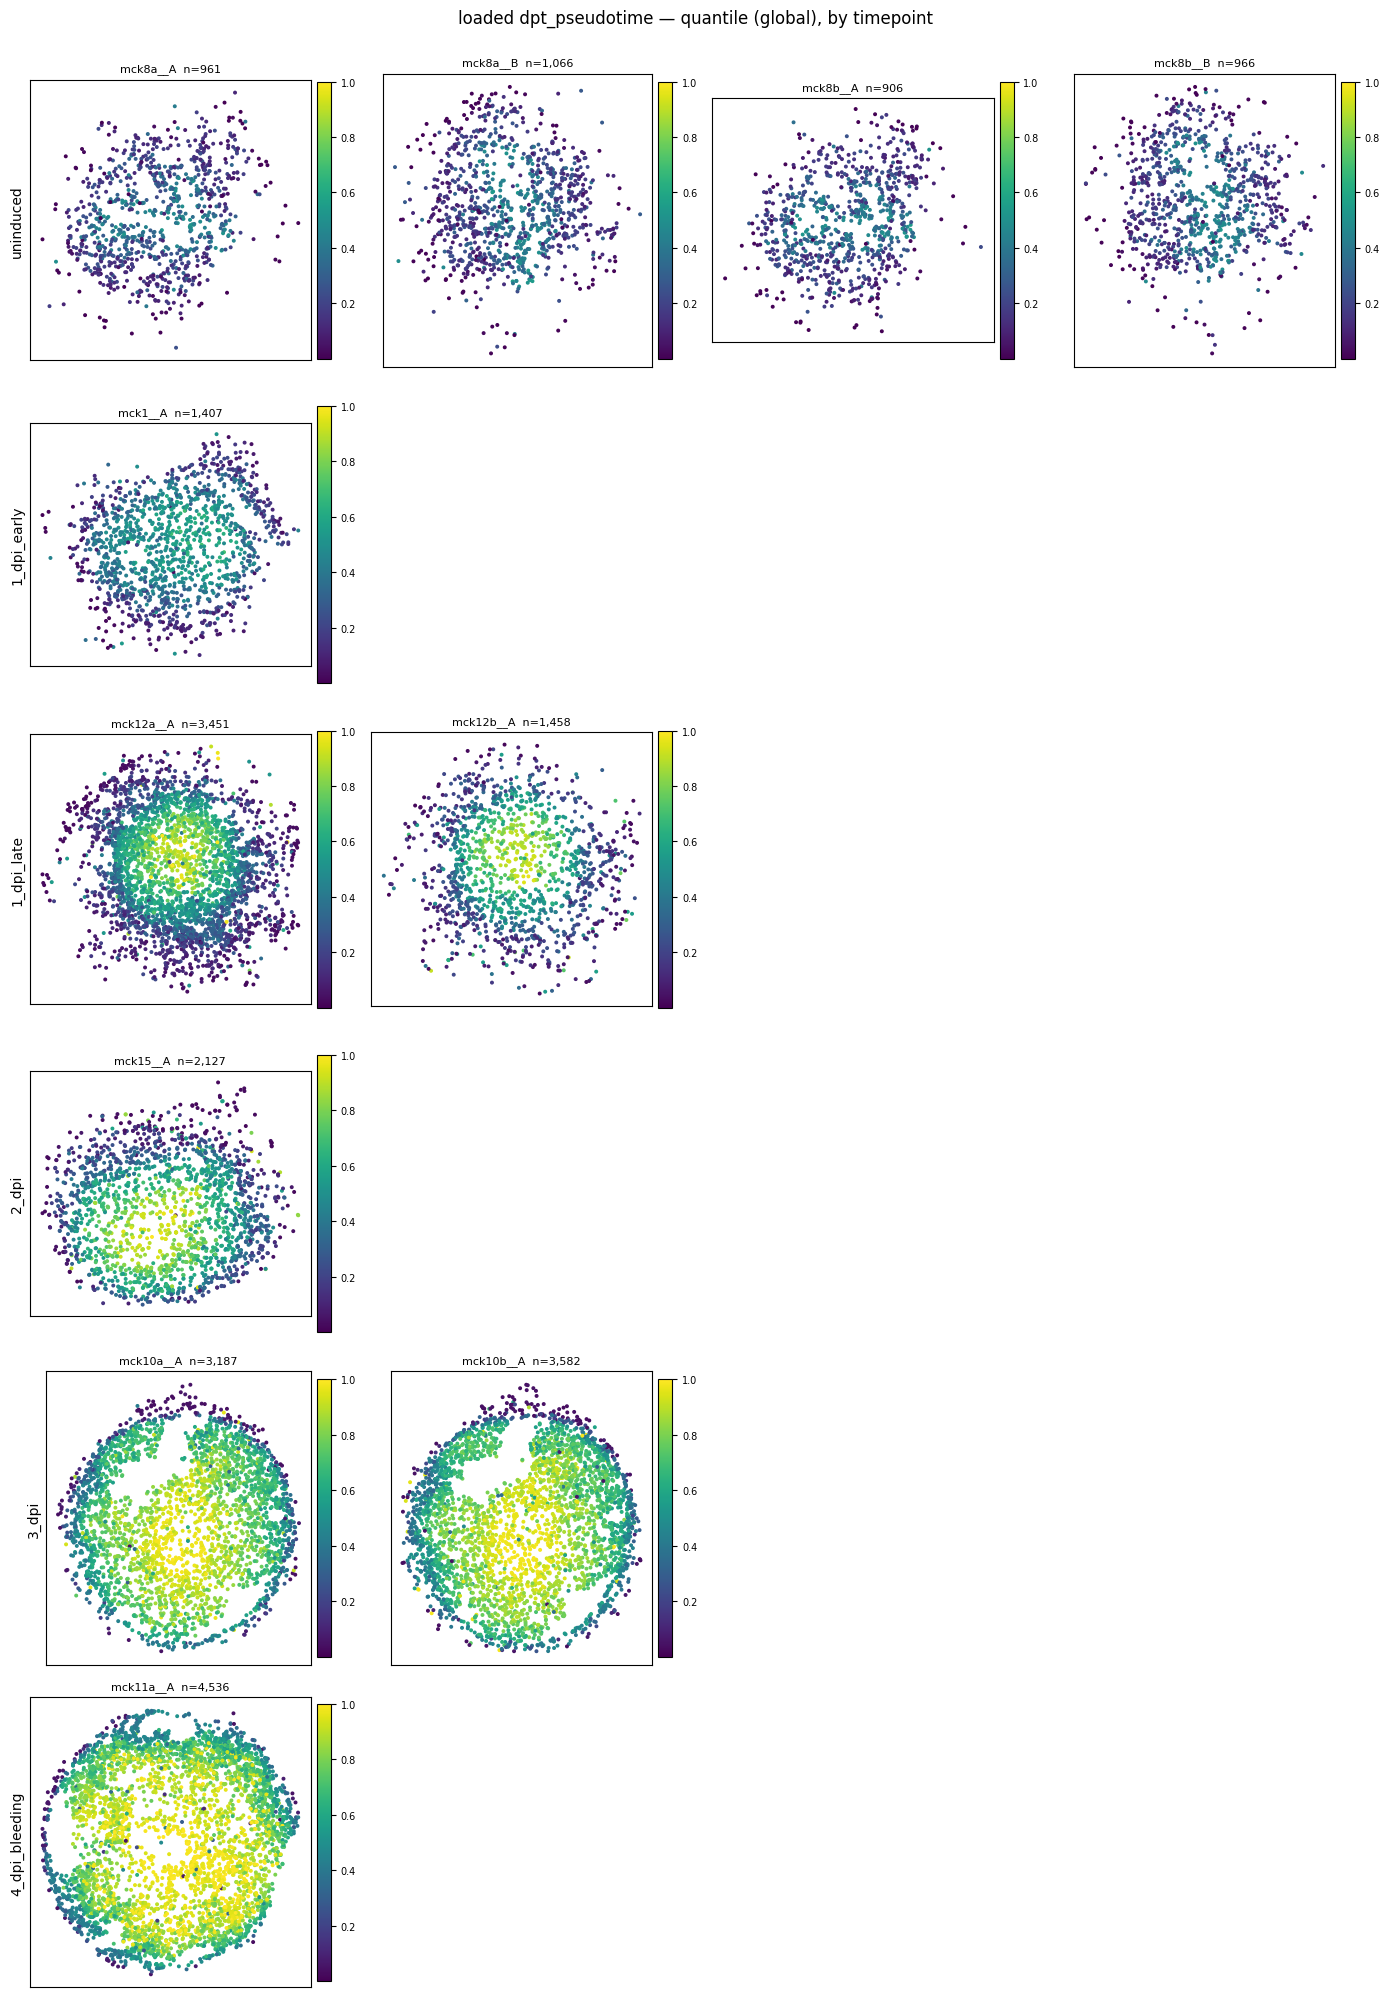

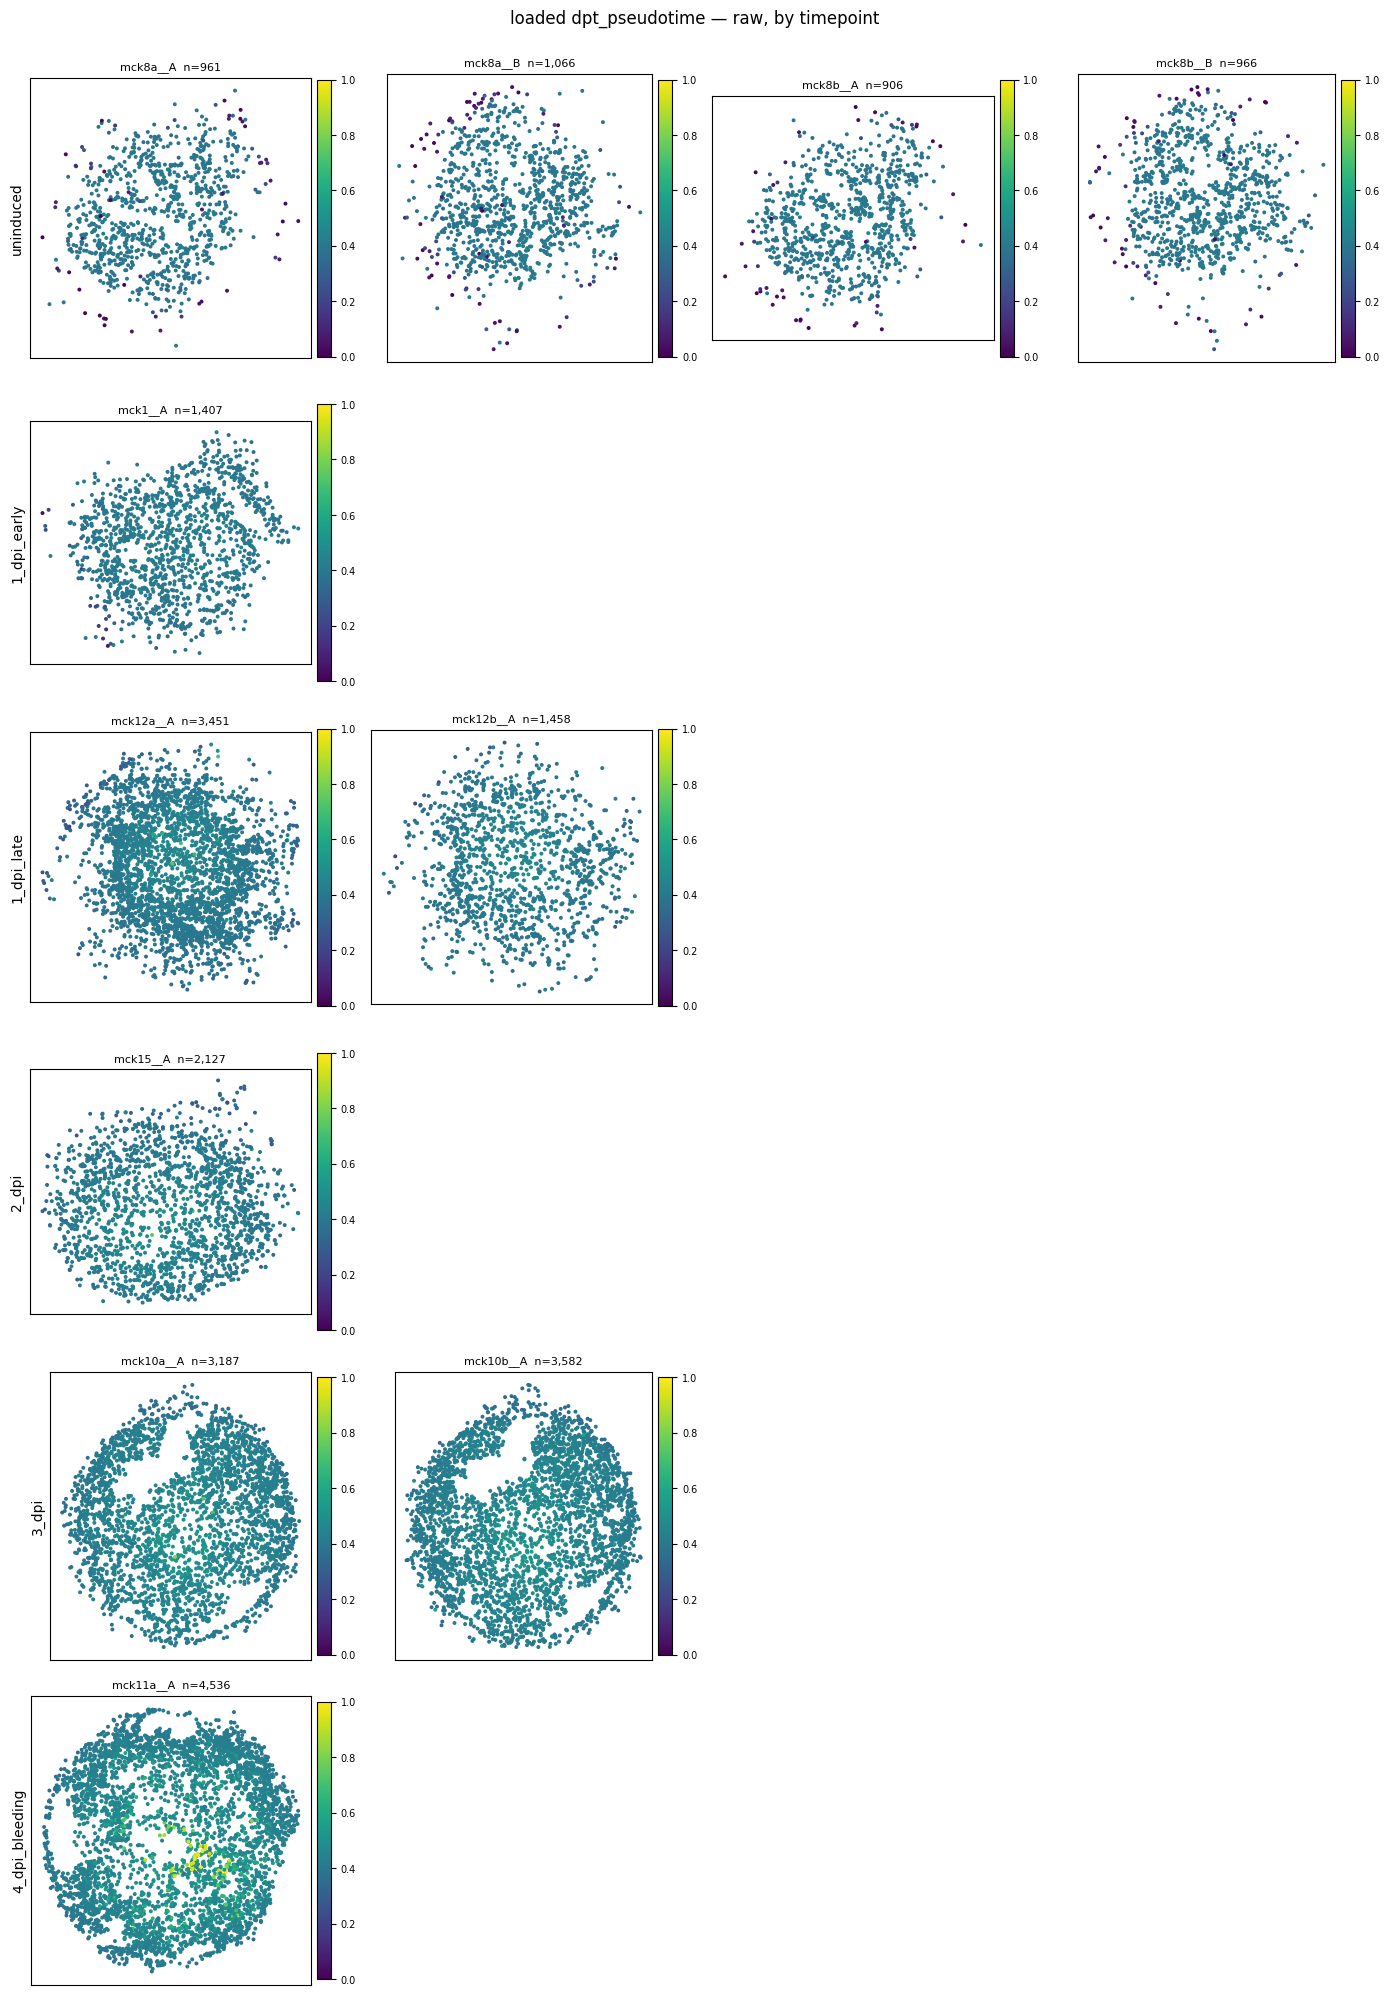

In [7]:
def spatial_by_timepoint(col="dpt_q", per=3.5, s=3.4):
    ncol = max(len(v) for v in SEC_BY_TP.values()); vmin, vmax = ((SP[col].min(), SP[col].max()) if col != "dpt_qsec" else (0, 1))
    fig, axes = plt.subplots(len(SEC_BY_TP), ncol, figsize=(per*ncol, per*len(SEC_BY_TP)*.95), squeeze=False)
    for i, (tp, sl) in enumerate(SEC_BY_TP.items()):
        for j in range(ncol):
            ax = axes[i][j]
            if j >= len(sl): ax.axis("off"); continue
            g = SP[SP.tissue_section == sl[j]]
            sm = ax.scatter(g.x_um_qc, g.y_um_qc, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{sl[j].replace(tp+'_','')}  n={len(g):,}", fontsize=8)
            if j == 0: ax.set_ylabel(tp, fontsize=10)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"loaded {PTCOL} — {LABS[col]}, by timepoint", y=1.0); fig.tight_layout(); return fig
_ = spatial_by_timepoint("dpt_q"); _ = spatial_by_timepoint(PTCOL)

## 6 — save the table

Per-cell pseudotime with both normalisations, labels, coordinates and section, so the figures can be rebuilt without re-reading the h5ad.

In [ ]:
res.to_csv(OUT/"loaded_pseudotime_mouse.csv")
json.dump(dict(source=str(SRC), column=PTCOL, n_cells=int(len(res)), n_with_pt=int(res[PTCOL].notna().sum()),
               n_with_pt_and_coords=int(len(SP)), sections=len(secs), provenance=prov, uns=uns_pt,
               checks=[dict(label=l, ok=o, got=g) for l, o, g, _ in CHECKS]),
          open(OUT/"loaded_pseudotime_mouse_report.json", "w"), indent=1, default=str)
bad = [l for l, o, _, _ in CHECKS if not o]
print("wrote", OUT/"loaded_pseudotime_mouse.csv")
print(f"{len(CHECKS)} checks | {len(bad)} FAILED" + (": " + "; ".join(bad) if bad else " — all passed"))